<a href="https://colab.research.google.com/github/danielcyber33/Analise-Dados-Colab/blob/main/Projeto_de_Transcriptoma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prática de Transcriptômica: expressão diferencial com DESeq2

**Introdução à Bioinformática – PPGED/IME · Aula 4 (Transcriptômica)**

Nesta prática, vamos descobrir quais genes mudam de atividade quando células humanas são tratadas com um corticoide.

**Os dados (conjunto `airway`)**
- Estudo de Himes e colaboradores (PLoS One, 2014), dados públicos no GEO (GSE52778).
- Células de músculo liso das vias aéreas (o músculo que envolve os brônquios) de **4 doadores**.
- As células de cada doador foram divididas em duas partes: **controle** e **tratada com dexametasona** (1 µM por 18 h).
- As leituras já foram mapeadas com o STAR no genoma humano (Ensembl 75) e contadas por gene. Partimos da **tabela de contagens**.

**Antes de começar**
1. No Colab: *Ambiente de execução → Alterar tipo de ambiente de execução → R*.
2. Execute as células **em ordem**, de cima para baixo (Shift + Enter).
3. Não é preciso escrever código: o objetivo é **executar e interpretar** cada resultado.

**Roteiro**
1. Preparação do ambiente
2. Conhecendo os dados
3. Desenho experimental
4. Controle de qualidade (PCA)
5. Análise de expressão diferencial
6. Resultados: três perguntas diferentes
7. Visualização
8. Exportar os resultados
9. Exercícios

## 1. Preparação do ambiente

Instalamos o **BiocManager** (o gerenciador de pacotes do Bioconductor) e, com ele, os pacotes da aula:
- **airway**: os dados do experimento;
- **DESeq2**: a ferramenta de análise de expressão diferencial;
- **ggplot2**: pacote de gráficos (já vem junto com o DESeq2).

⏱️ A instalação leva de 5 a 10 minutos. As mensagens em vermelho durante a instalação são normais.

In [1]:
# Instala o gerenciador de pacotes do Bioconductor e os pacotes da aula
install.packages("BiocManager")
BiocManager::install(c("airway", "DESeq2"))

library(airway)   # dados do experimento
library(DESeq2)   # análise de expressão diferencial
library(ggplot2)  # gráficos

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'BiocVersion', 'airway', 'DESeq2'

also installing the dependencies ‘XVector’, ‘formatR’, ‘abind’, ‘SparseArray’, ‘lambda.r’, ‘futile.options’, ‘Seqinfo’, ‘S4Arrays’, ‘DelayedArray’, ‘futile.logger’, ‘snow’, ‘BH’, ‘SummarizedExperiment’, ‘S4Vectors’, ‘IRanges’, ‘GenomicRanges’, ‘BiocGenerics’, ‘Biobase’, ‘BiocParallel’, ‘matrixStats’, ‘locfit’, ‘MatrixGenerics’, ‘RcppArmadillo’


Old packages: 'curl', 'gert', 'roxygen2', 'xfun', 'xtable'

Loading required package: SummarizedExperiment

Loading required package: MatrixGenerics

Loading required package: matrixStats


Attaching package: ‘MatrixGenerics’


The following object

## 2. Conhecendo os dados

O objeto `airway` guarda três peças juntas:
- **`colData`**: a ficha das amostras (doador, tratamento e códigos de catálogo do GEO e do SRA);
- **`assay`**: a tabela de contagens (genes nas linhas, amostras nas colunas);
- **`rowData`**: a ficha dos genes (nome, tipo, cromossomo, posição).

### 2.1 Ficha das amostras

Observe as colunas `cell` (doador) e `dex` (`untrt` = controle, `trt` = tratado). Cada doador aparece duas vezes: é um **desenho pareado**, com 4 réplicas biológicas por condição.

In [2]:
data(airway)       # carrega o experimento
colData(airway)    # ficha das amostras: doador (cell) e tratamento (dex)

DataFrame with 8 rows and 9 columns
           SampleName     cell      dex    albut        Run avgLength
             <factor> <factor> <factor> <factor>   <factor> <integer>
SRR1039508 GSM1275862  N61311     untrt    untrt SRR1039508       126
SRR1039509 GSM1275863  N61311     trt      untrt SRR1039509       126
SRR1039512 GSM1275866  N052611    untrt    untrt SRR1039512       126
SRR1039513 GSM1275867  N052611    trt      untrt SRR1039513        87
SRR1039516 GSM1275870  N080611    untrt    untrt SRR1039516       120
SRR1039517 GSM1275871  N080611    trt      untrt SRR1039517       126
SRR1039520 GSM1275874  N061011    untrt    untrt SRR1039520       101
SRR1039521 GSM1275875  N061011    trt      untrt SRR1039521        98
           Experiment    Sample    BioSample
             <factor>  <factor>     <factor>
SRR1039508  SRX384345 SRS508568 SAMN02422669
SRR1039509  SRX384346 SRS508567 SAMN02422675
SRR1039512  SRX384349 SRS508571 SAMN02422678
SRR1039513  SRX384350 SRS508572 SAMN024

### 2.2 Tabela de contagens

Cada número é **quantas leituras caíram naquele gene, naquela amostra**. Os genes são identificados pelo código do Ensembl (ENSG...).

⚠️ Esses números **ainda não podem ser comparados diretamente**: as amostras foram sequenciadas com profundidades diferentes. Quem corrige isso é o DESeq2.

In [3]:
head(assay(airway))   # primeiras linhas da tabela de contagens

,SRR1039508,SRR1039509,SRR1039512,SRR1039513,SRR1039516,SRR1039517,SRR1039520,SRR1039521
ENSG00000000003,679,448,873,408,1138,1047,770,572
ENSG00000000005,0,0,0,0,0,0,0,0
ENSG00000000419,467,515,621,365,587,799,417,508
ENSG00000000457,260,211,263,164,245,331,233,229
ENSG00000000460,60,55,40,35,78,63,76,60
ENSG00000000938,0,0,2,0,1,0,0,0


### 2.3 Tamanho do experimento

- `dim`: quantos genes e quantas amostras;
- `colSums`: total de leituras de cada amostra, em milhões (repare que varia bastante);
- `table`: quantos genes de cada tipo (nem todo "gene" codifica proteína).

In [4]:
dim(airway)                                         # genes × amostras
round(colSums(assay(airway)) / 1e6, 1)              # milhões de leituras por amostra
sort(table(rowData(airway)$gene_biotype), decreasing = TRUE)[1:8]   # tipos de gene mais comuns

[1] 63677     8

SRR1039508 SRR1039509 SRR1039512 SRR1039513 SRR1039516 SRR1039517 SRR1039520 
      20.6       18.8       25.3       15.2       24.4       30.8       19.1 
SRR1039521 
      21.2


protein_coding     pseudogene        lincRNA      antisense          miRNA 
         22810          15583           7340           5485           3361 
      misc_RNA          snRNA         snoRNA 
          2174           2067           1549 

## 3. Desenho experimental

Três passos:
1. Definimos **"não tratado"** como a referência. Assim, valores positivos de mudança significam "mais expresso no tratado".
2. Informamos o desenho `~ cell + dex`: o DESeq2 **desconta a diferença natural entre os doadores** e testa o efeito do tratamento. É como um ensaio de "antes e depois" no mesmo corpo de prova.
3. Removemos genes com menos de 10 leituras no total: eles não têm informação suficiente para o teste.

In [5]:
# Define "não tratado" (untrt) como referência de comparação
airway$dex <- relevel(airway$dex, ref = "untrt")

# Desenho: considerar o doador (cell) e testar o efeito do tratamento (dex)
dds <- DESeqDataSet(airway, design = ~ cell + dex)

# Remove genes quase sem leituras (pouca informação)
dds <- dds[rowSums(counts(dds)) >= 10, ]

nrow(dds)   # quantos genes restaram

[1] 22369

## 4. Controle de qualidade: PCA

Antes de procurar genes, verificamos se as amostras se comportam como esperado.

- **`vst`** transforma as contagens para uma escala parecida com a logarítmica, para que genes muito expressos não dominem o gráfico. Serve **só para visualização**.
- **PCA** resume os 500 genes que mais variam em dois eixos. **Cada ponto é uma amostra.** Pontos próximos = amostras com perfis parecidos.

**O que esperar:** o eixo horizontal (PC1) separa tratados e não tratados; o vertical (PC2) separa os doadores.

using ntop=500 top features by variance



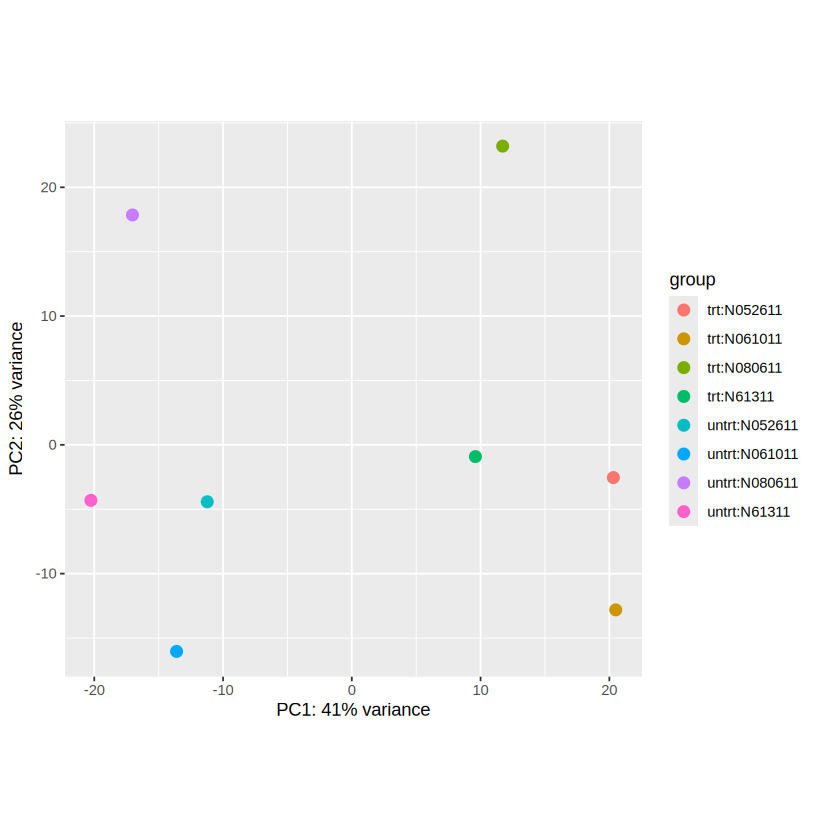

In [6]:
vsd <- vst(dds)                              # transforma os dados para visualização
plotPCA(vsd, intgroup = c("dex", "cell"))    # versão padrão do DESeq2

### 4.1 Uma PCA mais fácil de ler

Mesma análise, agora com **cor = doador** e **formato = tratamento**.

using ntop=500 top features by variance



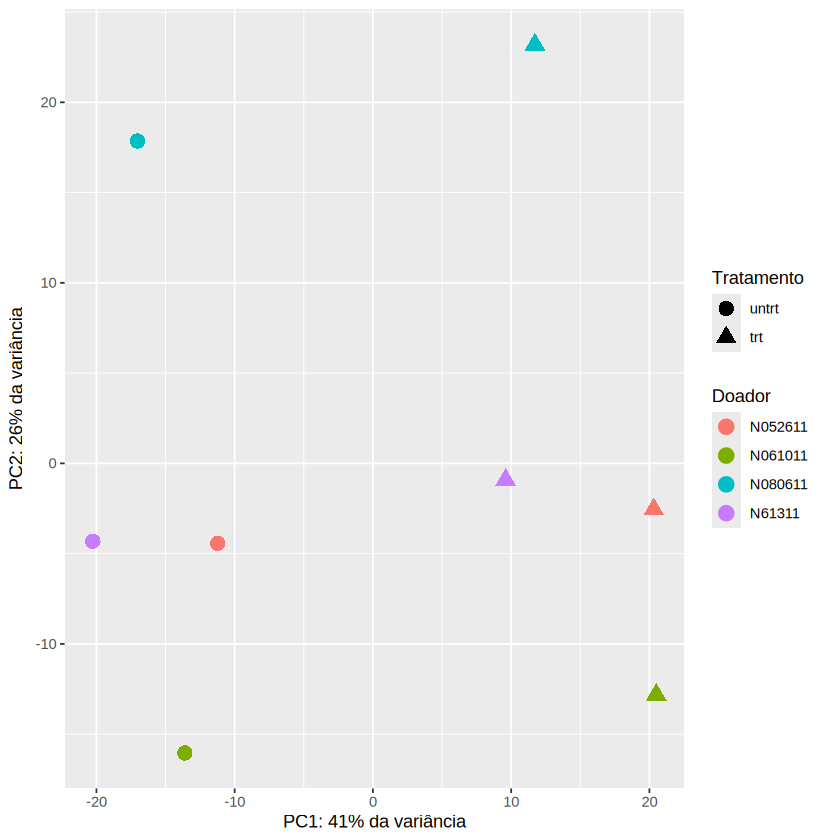

In [7]:
pca_df <- plotPCA(vsd, intgroup = c("dex", "cell"), returnData = TRUE)   # dados do gráfico
pv <- round(100 * attr(pca_df, "percentVar"))                             # % de variância de cada eixo

ggplot(pca_df, aes(x = PC1, y = PC2, color = cell, shape = dex)) +
  geom_point(size = 4) +
  labs(x = paste0("PC1: ", pv[1], "% da variância"),
       y = paste0("PC2: ", pv[2], "% da variância"),
       color = "Doador", shape = "Tratamento")

### 4.2 Quais genes formam os eixos?

Refazemos a mesma PCA "por dentro" para ver:
- quanto cada eixo explica (`summary`);
- quais genes têm mais **peso** no PC1, o eixo do tratamento.

Como os tratados ficaram à direita, genes com **peso positivo** tendem a estar **mais expressos nos tratados**; com peso negativo, menos expressos.

⚠️ Os pesos indicam **candidatos**, não a lista oficial de genes alterados. Essa vem do DESeq2 (seção 5).

In [8]:
mat <- assay(vsd)                                     # dados transformados (genes × amostras)
variancia <- apply(mat, 1, var)                       # variância de cada gene
top500 <- order(variancia, decreasing = TRUE)[1:500]  # os 500 que mais variam

pca <- prcomp(t(mat[top500, ]))                       # a mesma PCA do gráfico
summary(pca)                                          # confira: PC1 ≈ 41%, PC2 ≈ 26%

Importance of components:
                           PC1     PC2     PC3    PC4     PC5     PC6    PC7
Standard deviation     17.2128 13.7522 11.0381 9.6501 3.42033 2.74087 1.9945
Proportion of Variance  0.4095  0.2614  0.1684 0.1287 0.01617 0.01038 0.0055
Cumulative Proportion   0.4095  0.6709  0.8393 0.9679 0.98412 0.99450 1.0000
                             PC8
Standard deviation     1.047e-14
Proportion of Variance 0.000e+00
Cumulative Proportion  1.000e+00

In [9]:
pesos_PC1 <- pca$rotation[, "PC1"]                    # peso de cada gene no PC1

top_pos <- head(sort(pesos_PC1, decreasing = TRUE), 10)   # puxam para o lado dos tratados
top_neg <- head(sort(pesos_PC1), 10)                      # puxam para o lado dos não tratados

data.frame(gene = rowData(vsd)[names(top_pos), "gene_name"], peso = round(top_pos, 3))
data.frame(gene = rowData(vsd)[names(top_neg), "gene_name"], peso = round(top_neg, 3))

,gene,peso
,<chr>,<dbl>
ENSG00000109906,ZBTB16,0.136
ENSG00000152583,SPARCL1,0.122
ENSG00000211445,GPX3,0.119
ENSG00000101347,SAMHD1,0.117
ENSG00000096060,FKBP5,0.115
ENSG00000163884,KLF15,0.109
ENSG00000127954,STEAP4,0.109
ENSG00000171819,ANGPTL7,0.100
ENSG00000189221,MAOA,0.096


,gene,peso
,<chr>,<dbl>
ENSG00000162692,VCAM1,-0.096
ENSG00000178695,KCTD12,-0.077
ENSG00000124766,SOX4,-0.073
ENSG00000138316,ADAMTS14,-0.073
ENSG00000164742,ADCY1,-0.070
ENSG00000123610,TNFAIP6,-0.070
ENSG00000168398,BDKRB2,-0.069
ENSG00000214814,FER1L6,-0.067
ENSG00000126016,AMOT,-0.067


### 4.3 (Opcional) PC3 e PC4: as diferenças entre doadores

Os 4 primeiros eixos explicam quase 97% da variação. Separar 4 pessoas exige até 3 eixos, então PC2, PC3 e PC4 provavelmente refletem os **doadores**. Se as duas amostras de cada doador ficarem juntas, a interpretação se confirma.

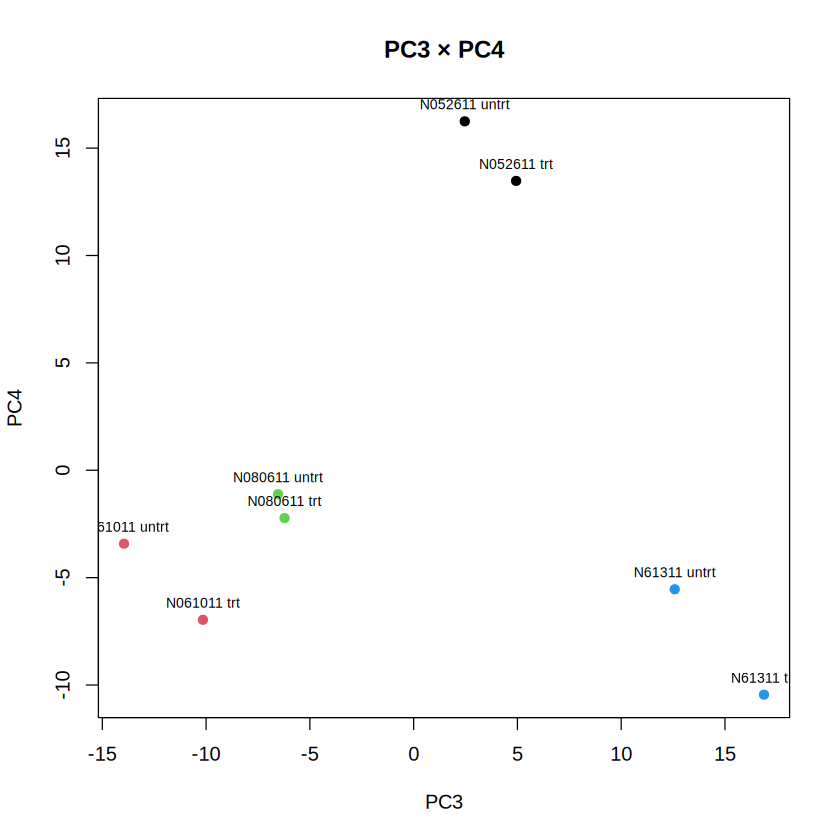

In [10]:
plot(pca$x[, "PC3"], pca$x[, "PC4"], pch = 19, col = as.integer(vsd$cell),
     xlab = "PC3", ylab = "PC4", main = "PC3 × PC4")
text(pca$x[, "PC3"], pca$x[, "PC4"], labels = paste(vsd$cell, vsd$dex), pos = 3, cex = 0.7)

## 5. Análise de expressão diferencial

A função `DESeq` faz tudo de uma vez:
1. **Normalização** (`estimating size factors`): corrige a diferença no total de leituras entre amostras.
2. **Dispersão** (`estimating dispersions`): mede o "ruído" de cada gene entre réplicas, "emprestando informação" dos milhares de genes para compensar as poucas réplicas.
3. **Teste** (`fitting model and testing`): para cada gene, verifica se o tratamento mudou a expressão além do ruído.

O `summary` mostra o placar: quantos genes subiram e desceram com padj < 0,05.

In [11]:
dds <- DESeq(dds)                  # normaliza, estima variação e testa cada gene
res <- results(dds, alpha = 0.05)  # resultados com corte de padj < 0,05
summary(res)                       # quantos genes subiram e quantos desceram

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing




out of 22369 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 2208, 9.9%
LFC < 0 (down)     : 1822, 8.1%
outliers [1]       : 0, 0%
low counts [2]     : 5204, 23%
(mean count < 6)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



### 5.1 Fatores de normalização

Um número por amostra. Acima de 1 = amostra com mais leituras que a média; abaixo de 1 = com menos.

In [12]:
round(sizeFactors(dds), 2)

SRR1039508 SRR1039509 SRR1039512 SRR1039513 SRR1039516 SRR1039517 SRR1039520 
      1.02       0.90       1.18       0.67       1.18       1.40       0.92 
SRR1039521 
      0.94

## 6. Resultados: três perguntas diferentes

| Coluna | Significado |
|---|---|
| `baseMean` | expressão média do gene (normalizada) |
| `log2FoldChange` | quanto mudou, em log2: +1 = dobrou; −1 = caiu pela metade; +3 = 8× |
| `lfcSE` | incerteza (erro padrão) do log2FoldChange |
| `padj` | p-valor corrigido para milhares de testes; < 0,05 = confiável |

Vamos ordenar os genes de três formas, porque cada uma responde a uma pergunta diferente.

### 6.1 Quais mudanças são mais **certas**? (ordenado por padj)

In [13]:
res_ord <- res[order(res$padj), ]               # do mais ao menos significativo

top_padj <- as.data.frame(head(res_ord, 10))
top_padj$gene <- rowData(dds)[rownames(top_padj), "gene_name"]
top_padj[, c("gene", "baseMean", "log2FoldChange", "lfcSE", "padj")]

,gene,baseMean,log2FoldChange,lfcSE,padj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
ENSG00000152583,SPARCL1,997.4447,4.574967,0.18424142,7.055960e-132
ENSG00000165995,CACNB2,495.0957,3.291099,0.13305274,3.830700e-131
ENSG00000120129,DUSP1,3409.0384,2.947850,0.12187644,1.735862e-125
ENSG00000101347,SAMHD1,12703.4128,3.767022,0.15599195,3.296820e-125
ENSG00000189221,MAOA,2341.7807,3.353655,0.14218099,1.789522e-119
ENSG00000211445,GPX3,12285.7001,3.730439,0.16639840,7.395423e-108
ENSG00000157214,STEAP2,3009.2729,1.976796,0.09042512,1.493686e-102
ENSG00000162614,NEXN,5393.1145,2.035697,0.09468470,3.358895e-99
ENSG00000125148,MT2A,3656.2674,2.211006,0.10609056,3.527682e-93


### 6.2 Quais genes mudaram **mais**? (ordenado por log2FoldChange)

⚠️ Esta lista favorece genes **pouco expressos** (baseMean baixo): sair de 1 para 30 leituras já é "30 vezes". Repare no `lfcSE` alto desses genes, sinal de estimativa incerta.

In [14]:
sig <- res[which(res$padj < 0.05), ]                                       # só os significativos
maiores <- as.data.frame(head(sig[order(sig$log2FoldChange, decreasing = TRUE), ], 10))
maiores$gene <- rowData(dds)[rownames(maiores), "gene_name"]
maiores[, c("gene", "baseMean", "log2FoldChange", "lfcSE", "padj")]

,gene,baseMean,log2FoldChange,lfcSE,padj
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
ENSG00000179593,ALOX15B,67.242812,9.505998,1.0536853,1.123604e-17
ENSG00000109906,ZBTB16,385.071328,7.352659,0.5363926,2.210308e-40
ENSG00000250978,RP11-357D18.1,56.318557,6.326641,0.6762590,5.743863e-19
ENSG00000127954,STEAP4,286.388753,5.207195,0.4930895,4.820970e-24
ENSG00000249364,RP11-434D9.1,8.839183,5.092763,1.1533113,1.075740e-04
ENSG00000171819,ANGPTL7,254.882599,5.081610,0.7573022,4.929599e-10
ENSG00000100033,PRODH,55.363920,4.889871,0.5203539,3.893930e-19
ENSG00000260802,LINC00890,6.723144,4.883578,1.1930662,3.914881e-04
ENSG00000168309,FAM107A,159.530276,4.834999,0.3306346,6.217656e-46


### 6.3 Quais mudaram mais **de forma confiável**? (log2FoldChange encolhido)

A função `lfcShrink` "encolhe" em direção a zero os log2FoldChange incertos e preserva os bem medidos. É a melhor lista para escolher **candidatos**.

⏱️ Instala o pacote `apeglm` (1 a 2 minutos na primeira vez).

In [ ]:
BiocManager::install("apeglm")
resultsNames(dds)                                   # nome do coeficiente: "dex_trt_vs_untrt"

res_shr <- lfcShrink(dds, coef = "dex_trt_vs_untrt", type = "apeglm")

sig_shr <- res_shr[which(res_shr$padj < 0.05), ]
top_shr <- as.data.frame(head(sig_shr[order(sig_shr$log2FoldChange, decreasing = TRUE), ], 10))
top_shr$gene <- rowData(dds)[rownames(top_shr), "gene_name"]
top_shr[, c("gene", "baseMean", "log2FoldChange", "lfcSE", "padj")]

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Installing package(s) 'apeglm'

also installing the dependencies ‘numDeriv’, ‘bdsmatrix’, ‘mvtnorm’, ‘plyr’, ‘coda’, ‘bbmle’, ‘emdbook’, ‘RcppEigen’, ‘RcppNumerical’




### 6.4 Exigindo uma mudança mínima no teste

O critério padj < 0,05 inclui mudanças pequenas (10%, 20%). Com `lfcThreshold = 1`, o DESeq2 testa se o gene mudou **mais do que o dobro**. Compare o placar com o da seção 5.

In [ ]:
res_lfc1 <- results(dds, alpha = 0.05, lfcThreshold = 1)
summary(res_lfc1)

## 7. Visualização

- **MA plot**: expressão média (eixo X) × mudança (eixo Y). Pontos coloridos = significativos.
- **Volcano plot**: tamanho da mudança (eixo X) × certeza estatística (eixo Y). Em vermelho, genes com padj < 0,05 **e** mudança acima de 2×. Os 10 mais significativos aparecem com nome.

In [ ]:
plotMA(res, ylim = c(-5, 5))

In [ ]:
vol <- as.data.frame(res)
vol <- vol[!is.na(vol$padj), ]                                   # remove genes não testados
vol$gene <- rowData(dds)[rownames(vol), "gene_name"]
destaque <- vol$padj < 0.05 & abs(vol$log2FoldChange) > 1

plot(vol$log2FoldChange, -log10(vol$padj), pch = 20, cex = 0.6,
     col = ifelse(destaque, "red", "grey"),
     xlab = "log2 Fold Change", ylab = "-log10(padj)",
     main = "Genes alterados pela dexametasona")
abline(v = c(-1, 1), h = -log10(0.05), lty = 2)                  # limites: 2× e padj = 0,05

top <- head(vol[order(vol$padj), ], 10)                           # 10 mais significativos
text(top$log2FoldChange, -log10(top$padj), labels = top$gene, pos = 3, cex = 0.7)

## 8. Exportar os resultados

Gera uma planilha com todos os genes, já com o nome de cada um. Para baixar: no Colab, clique no ícone de pasta (barra lateral esquerda), depois nos três pontinhos ao lado de `resultados_DESeq2.csv` → *Fazer download*.

In [ ]:
tabela <- as.data.frame(res_ord)
tabela$gene <- rowData(dds)[rownames(tabela), "gene_name"]
tabela <- tabela[, c("gene", setdiff(names(tabela), "gene"))]    # nome do gene na 1ª coluna

write.csv(tabela, "resultados_DESeq2.csv")

## 9. Exercícios

1. Na seção 6.4, troque `lfcThreshold = 1` por `lfcThreshold = 2`. Quantos genes continuam significativos?
2. Compare as listas das seções 4.2 (pesos do PC1), 6.1 e 6.3. Quais genes aparecem em mais de uma? Por quê?
3. Escolha um gene da seção 6.3, pesquise o código ENSG em [ensembl.org](https://www.ensembl.org) e descreva sua função em 3 linhas.
4. **Desafio:** repita a análise com o pacote **edgeR** e compare os 10 primeiros genes com os do DESeq2.